In [1]:
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_core.messages import SystemMessage
from langchain_core.runnables import RunnableConfig 

from langgraph.graph import StateGraph, START, END, MessagesState
from langgraph.store.memory import InMemoryStore
from langgraph.store.base import BaseStore
from dotenv import load_dotenv

c:\Users\Ashutosh Pandey\Desktop\Machine Learning\LangGraph-In-Depth\LangGraph\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
load_dotenv()

True

# Creating Longterm memory story with seed memory(done before the graph)

In [3]:
store = InMemoryStore()

user_id = "ui"

# we will create the namespace
user_details = ("user", user_id, "details")

In [4]:
# Now we will fill the profile details.
store.put(user_details, "profile-1", {"data": " Name: Ashutosh Pandey "})
store.put(user_details, "profile-2", {"data": "profession: Software Engineer & AI Engineer"})
store.put(user_details, "skill-set", {"data": "C++, Python, Agents, Langfamily"})
store.put(user_details, "preferences", {"data": "likes to study and learn new things"})

In [5]:
# adding the system prompt template

SYSTEM_PROMPT_TEMPLATE = """You are a helpful assistant with memory capabilities.
If user-specific memory is available, use it to personalize 
your responses based on what you know about the user.

Your goal is to provide relevant, friendly, and tailored 
assistance that reflects the user’s preferences, context, and past interactions.

If the user’s name or relevant personal context is available, always personalize your responses by:
    – Always Address the user by name (e.g., "Sure, Nitish...") when appropriate
    – Referencing known projects, tools, or preferences (e.g., "your MCP  server python based project")
    – Adjusting the tone to feel friendly, natural, and directly aimed at the user

Avoid generic phrasing when personalization is possible. For example, instead of "In TypeScript apps..." 
say "Since your project is built with TypeScript..."

Use personalization especially in:
    – Greetings and transitions
    – Help or guidance tailored to tools and frameworks the user uses
    – Follow-up messages that continue from past context

Always ensure that personalization is based only on known user details and not assumed.

In the end suggest 3 relevant further questions based on the current response and user profile

The user’s memory (which may be empty) is provided as: {user_details_content} """

In [6]:
from langchain_groq import ChatGroq
# now we will create the LLM
LLM = ChatGroq(model="openai/gpt-oss-120b", temperature=0.7)

In [12]:
# now we will write our node function here
def chat_node(state: MessagesState, config: RunnableConfig, store: BaseStore):
    
    #this will get us the user id.
    user_id = config["configurable"]["user_id"]
    
    user_details = ("user", user_id, "details")
    # first we will search the store and get all the memories
    items = store.search(user_id)
    
    # now the below code would be for like convert memory items into a string blok for {user_details_content}
    # keep it dead simple for teaching.
    
    if items:
        user_details_content = "\n".join(f"-{it.value.get('data', "")}" for it in items)
    # with this we will get the memory block seperated by hypen if there 
    else:
        user_details_content =""  # else say prompt is empty
        
    #now we get all the memory in the form of a string 
    
    # now we will fill the system prompt using this memory
    system_prompt = SYSTEM_PROMPT_TEMPLATE.format(user_details_content=user_details_content)
    
    # we will make a system message with this prompt
    system_msg = SystemMessage(content=system_prompt)
    
    #now we will give this to llm
    response = LLM.invoke([system_msg]+ state["messages"])
    
    return {"messages": [response]}

In [13]:
graph = StateGraph(MessagesState)
# we will build our node
graph.add_node("chat_node", chat_node)
#now we will add the edges
graph.add_edge(START, "chat_node")
graph.add_edge("chat_node", END)

#compiling the graph
chatbot = graph.compile(store=store)

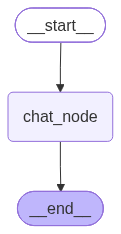

In [18]:
chatbot 

In [17]:
config = {"configurable": {"user_id": "u1"}}

result = chatbot.invoke({"messages": [{"role": "user", "content": "can you explain gen ai in simple terms"}]}, config)

print(result["messages"][-1].content)

Sure! Let’s break down **generative AI** in a way that’s easy to grasp.

### What It Is
Generative AI is a type of artificial intelligence that **creates new content**—like text, images, music, or even code—rather than just analyzing or classifying existing data. Think of it as a very clever assistant that can *imagine* and *produce* things for you.

### How It Works (Simplified)
1. **Learning Phase**  
   - The AI is fed a huge amount of examples (e.g., millions of sentences, photos, songs).  
   - It learns patterns, structures, and relationships within that data.

2. **Generation Phase**  
   - When you give it a prompt (like “Write a short story about a robot”), it uses what it learned to **predict the next piece of content** step‑by‑step until the output is complete.  
   - It’s essentially guessing the most likely next word, pixel, note, etc., based on the patterns it has seen.

### Everyday Analogies
- **Autocomplete on your phone:** It predicts the next word you might type. Gen